[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ichristov/viscoelastic-startup/blob/main/notebooks/christov_2015_oldroydb_stokes2.ipynb)

# LEARNING OBJECTIVE

After exploring this notebook, you will be able to regenerate, from scratch, the solution of the transient version of Stokes' second problem (a plate suddenly set into oscillation) for an Oldroyd-B fluid in a half-space, with its early-time asymptotics from Appendix A of [Christov (2015)](https://doi.org/10.1139/cjp-2015-0374) and its approach to the late-time solution of [Hopkins & de Bruyn (2014)](https://doi.org/10.1139/cjp-2013-0334). You will verify the solution against a numerical inversion of the Laplace transform, a finite-difference scheme and the Duhamel integral that Christov (2015) proposes, reproduce Fig. 1 of Hopkins & de Bruyn (2014) and of Aksel _et al._ (2006), and identify the problem that the erroneous solution of Aksel _et al._ (2006) actually solves.

The lesson of this notebook is that the backflow Aksel _et al._ (2006) attribute to the fluid's elasticity comes from the plate: their solution is exact for a plate that moves backward.

# PRELIMINARIES

This notebook uses [NumPy](https://numpy.org) ([Harris _et al._, 2020](https://doi.org/10.1038/s41586-020-2649-2)), [SciPy](https://scipy.org) ([Virtanen _et al._, 2020](https://doi.org/10.1038/s41592-019-0686-2)), [SymPy](https://www.sympy.org) ([Meurer _et al._, 2017](https://doi.org/10.7717/peerj-cs.103)), [Matplotlib](https://matplotlib.org) ([Hunter, 2007](https://doi.org/10.1109/MCSE.2007.55)) and [mpmath](https://mpmath.org) ([mpmath development team, 2023](https://mpmath.org/)).

[run the next cell to setup Python environment customizations and load packages]

In [1]:
# interactive plots setup
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

# sympy setup
import sympy as sp
sp.init_printing()
from sympy.vector import *

# plotting customizations
from matplotlib import colormaps, animation, rc
from matplotlib import pyplot as plt
size=16
params = {'legend.fontsize': 'large',
#          'figure.figsize': (20,8),
          'axes.labelsize': size,
          'axes.titlesize': size,
          'xtick.labelsize': size*0.875,
          'ytick.labelsize': size*0.875,
          'axes.titlepad': 25}
plt.rcParams.update(params)
%matplotlib inline

# for animations
from IPython.display import HTML

# numerics
import numpy as np
from scipy.integrate import quad
from scipy.special import erfc
from scipy.linalg import solve_banded
import mpmath as mp
import os

# for Colab only: to save plots as files and download them
#from google.colab import files

## Credit

Initial version of this notebook written by [Ivan C. Christov](https://christov.tmnt-lab.org), Purdue University.

Reproducing results of I. C. Christov.

# THE PROBLEM

The velocity $u(y,t)$ and shear stress $\tau(y,t)$ of an Oldroyd-B fluid above a plate that starts to oscillate at $t = 0$, the oscillating plate of [Stokes (1850)](https://archive.org/details/b22464074/page/13/mode/2up), art. 7, started from rest, Eqs. (14)&ndash;(17) of Hopkins & de Bruyn (2014) in unidirectional flow, with the start-up made explicit as in Appendix A of Christov (2015):
\begin{align*}
    \frac{\partial u}{\partial t} &= \frac{\partial \tau}{\partial y}, & (y,t)\in(0,\infty)\times(0,\infty),\\
    \tau + \lambda_1\frac{\partial \tau}{\partial t} &= B\left(\frac{\partial u}{\partial y} + \lambda_2\frac{\partial^2 u}{\partial t\,\partial y}\right), & (y,t)\in(0,\infty)\times(0,\infty),\\
    u(0,t) &= H(t)\cos t,\qquad u(\infty,t) = 0, & t>0,\\
    u(y,0) &= 0,\qquad\qquad\qquad \tau(y,0) = 0, & y>0,
\end{align*}
where $H(t)$ is the [Heaviside step function](https://en.wikipedia.org/wiki/Heaviside_step_function). Time is scaled by $1/\omega$ ($\omega$ the plate's frequency), velocity by the plate's amplitude $U$, length by $U/\omega$ and stress by $\rho U^2$; $\lambda_1$ and $\lambda_2$ are the relaxation and retardation times scaled by $1/\omega$, and $B = \eta_0\omega/(\rho U^2)$. Eliminating $\tau$,
\begin{align*}
    \left(1+\lambda_1\frac{\partial}{\partial t}\right)\frac{\partial u}{\partial t} &= B\left(1+\lambda_2\frac{\partial}{\partial t}\right)\frac{\partial^2 u}{\partial y^2}, &\quad (y,t)\in(0,\infty)\times(0,\infty),\\
    u(y,0) &= \frac{\partial u}{\partial t}(y,0) = 0, & y>0.
\end{align*}
Rescaling $y$ by $\sqrt{B}$ removes $B$, so I set $B = 1$, as in all figures of Hopkins & de Bruyn (2014) and in Eq. (A1a) of Christov (2015). This is also Eq. (3.1) of Aksel _et al._ (2006), in the same scaling: their $v/V$, $\omega t$, $\lambda\omega$ and $\lambda_r\omega$ are $u$, $t$, $\lambda_1$ and $\lambda_2$ here, and their $\nu$ is $B = 1$. They plot against a $Y$ they do not define. In their Fig. 2 ($\lambda_1 = 3$, $\lambda_2 = 0$), the elastic front is at $Y \approx 0.9$ when $t = \pi/2$, which fits $Y = y\sqrt{\omega/\nu}$, so their $Y$ is $y$ here.

The plate velocity jumps from 0 to 1 at $t = 0$, so its derivative contains the [Dirac delta](https://en.wikipedia.org/wiki/Dirac_delta_function) $\delta(t)$:
$$
    \frac{\mathrm{d}}{\mathrm{d}t}\left[H(t)\cos t\right] = \delta(t) - H(t)\sin t.
$$
A Fourier sine transform in $y$ brings in the boundary value $u(0,t)$, and the retardation term $\lambda_2\,\partial^3u/\partial t\partial y^2$ brings in its time derivative, $\delta(t)$ included. Dropping this $\delta(t)$ is the error corrected below. The next cell holds the coefficients of Aksel _et al._ (2006), their breakpoints $a$ and $b$ of Eq. (3.9), where the Fourier modes change from overdamped to oscillatory, and the damped modes, written so that they do not overflow.

In [2]:
# Generic helpers, used by the erroneous solution below and by the correct one
# Eqs. (3.8), (3.9), (3.11) and (3.12) of Aksel et al. (2006), with omega = nu = V = 1, lambda = lam1, lambda_r = alpha = lam2
def A_coef(xi, lam1, lam2):
    """A(xi) of Eq. (3.8) of Aksel et al. (2006)."""
    return xi*((1 + lam2**2)*xi**2 + lam2 - lam1)/((xi**2 - lam1)**2 + (1 + lam2*xi**2)**2)

def B_coef(xi, lam1, lam2):
    """B(xi) of Eq. (3.9) of Aksel et al. (2006)."""
    return xi*(1 + lam1*lam2)/((xi**2 - lam1)**2 + (1 + lam2*xi**2)**2)

def C_coef(xi, lam1, lam2):
    """C(xi) of Eq. (3.11) of Aksel et al. (2006), in its second (closed) form."""
    return (1 + lam1**2 + xi**2*(lam2 - lam1))/(xi*((xi**2 - lam1)**2 + (1 + lam2*xi**2)**2))

def breakpoints(lam1, lam2):
    """Integration edges: 0 and, where they exist, a and b of Eq. (3.9) of Aksel et al. (2006)."""
    if lam1 > lam2 and lam2 > 0:
        return [0.0, 1/(np.sqrt(lam1) + np.sqrt(lam1 - lam2)), 1/(np.sqrt(lam1) - np.sqrt(lam1 - lam2))]
    if lam1 > 0 and lam2 == 0:
        return [0.0, 1/(2*np.sqrt(lam1))]   # b is infinite for a Maxwell fluid
    return [0.0, 1.0]   # no breakpoints: split at 1 only to help the quadrature

def damped_modes(xi, t, lam1, lam2):
    """exp(-g t) [cosh(h t), sinh(h t)/beta], or [cos(h t), sin(h t)/gamma] where the modes oscillate; Eq. (3.12)."""
    g = (1 + lam2*xi**2)/(2*lam1)
    D = (1 + lam2*xi**2)**2 - 4*lam1*xi**2   # beta^2 if D > 0, -gamma^2 if D < 0
    if abs(D) < 1e-12:
        # xi = a or b: the limit beta -> 0
        return np.exp(-g*t), np.exp(-g*t)*t/(2*lam1)
    if D > 0:
        beta = np.sqrt(D)
        h = beta/(2*lam1)
        # exp(-g t) cosh(h t) and exp(-g t) sinh(h t), written so that they do not overflow
        ec = 0.5*(np.exp((h - g)*t) + np.exp(-(h + g)*t))
        es = 0.5*(np.exp((h - g)*t) - np.exp(-(h + g)*t))
        return ec, es/beta
    gamma = np.sqrt(-D)
    h = gamma/(2*lam1)
    return np.exp(-g*t)*np.cos(h*t), np.exp(-g*t)*np.sin(h*t)/gamma

def damped_Phi(xi, t, lam1, lam2):
    """exp(-t/(2 lam1)) Phi(xi,t) exp(-lam2 xi^2 t/(2 lam1)), Phi of Eq. (3.12), all three cases."""
    ec, es = damped_modes(xi, t, lam1, lam2)
    return A_coef(xi, lam1, lam2)*(ec + (1 + lam2*xi**2)*es) + 2*lam1*B_coef(xi, lam1, lam2)*es

def fourier_sine(func, y, edges):
    """The integral of func(xi) sin(y xi) over (0, infinity), split at the given edges."""
    total = 0.0
    for i in range(len(edges) - 1):
        total = total + quad(lambda xi: func(xi)*np.sin(xi*y), edges[i], edges[i+1], limit=200)[0]
    # the tail decays like sin(y xi)/xi: Fourier-weighted quadrature
    total = total + quad(func, edges[-1], np.inf, weight='sin', wvar=y, limlst=100)[0]
    return total

def profile(func, y, t, lam1, lam2):
    """Evaluate a point-wise solution func(y, t, lam1, lam2) on an array of y."""
    u = np.zeros_like(y)
    for j in range(len(y)):
        u[j] = func(y[j], t, lam1, lam2)
    return u

# THE ERRONEOUS SOLUTION

> &#x26A0;&#xFE0F; **ERRONEOUS SOLUTION, reproduced as printed** in Eqs. (3.5) and (3.10)&ndash;(3.12) of Aksel, Fetecau & Scholle (2006) ([doi:10.1007/s00033-006-0063-8](https://doi.org/10.1007/s00033-006-0063-8)), pp. 817&ndash;818. Their subsidiary equation, Eq. (3.5), lacks the term $\sqrt{2/\pi}\,\lambda_2\xi\,\delta(t)$ on its right-hand side, the same omission that [I. C. Christov & P. M. Jordan (2012)](https://arxiv.org/abs/1111.4464) corrected for a second-grade fluid. It is shown below to be wrong.

Aksel _et al._ (2006) take the Fourier sine transform $u_s(\xi,t)$ of $u(y,t)$ in $y$ (their $v_s$), and find, in the notation here,
\begin{align*}
    \lambda_1\frac{\partial^2 u_s}{\partial t^2} + (1+\lambda_2\xi^2)\frac{\partial u_s}{\partial t} + \xi^2 u_s &= \sqrt{\frac{2}{\pi}}\,\xi\left(\cos t - \lambda_2\sin t\right), & \xi,t>0,\\
    u_s(\xi,0) &= \frac{\partial u_s}{\partial t}(\xi,0) = 0, & \xi>0,
\end{align*}
whose inverse is their Eq. (3.10),
\begin{align*}
    u(y,t) = \cos t &- \frac{2}{\pi}\cos t\int_0^\infty C(\xi)\sin(y\xi)\,\mathrm{d}\xi + \frac{2}{\pi}\sin t\int_0^\infty B(\xi)\sin(y\xi)\,\mathrm{d}\xi\\
    &- \frac{2}{\pi}\exp\left(-\frac{t}{2\lambda_1}\right)\int_0^\infty \Phi(\xi,t)\exp\left(-\frac{\lambda_2\xi^2 t}{2\lambda_1}\right)\sin(y\xi)\,\mathrm{d}\xi,
\end{align*}
with, from their Eqs. (3.8), (3.9) and (3.11),
\begin{align*}
    A(\xi) &= \xi\,\frac{(1+\lambda_2^2)\xi^2 + \lambda_2 - \lambda_1}{(\xi^2 - \lambda_1)^2 + (1+\lambda_2\xi^2)^2},\\
    B(\xi) &= \xi\,\frac{1 + \lambda_1\lambda_2}{(\xi^2 - \lambda_1)^2 + (1+\lambda_2\xi^2)^2},\\
    C(\xi) &= \frac{1 - \xi A(\xi)}{\xi} = \frac{1 + \lambda_1^2 + (\lambda_2 - \lambda_1)\xi^2}{\xi\left[(\xi^2 - \lambda_1)^2 + (1+\lambda_2\xi^2)^2\right]},
\end{align*}
and, from their Eq. (3.12), with $\beta = \sqrt{(1+\lambda_2\xi^2)^2 - 4\lambda_1\xi^2}$ and $\gamma = \sqrt{4\lambda_1\xi^2 - (1+\lambda_2\xi^2)^2}$,
$$
    \Phi(\xi,t) =
    \begin{cases}
        A(\xi)\left[\cosh\left(\frac{\beta t}{2\lambda_1}\right) + \frac{1+\lambda_2\xi^2}{\beta}\sinh\left(\frac{\beta t}{2\lambda_1}\right)\right] + \frac{2\lambda_1 B(\xi)}{\beta}\sinh\left(\frac{\beta t}{2\lambda_1}\right), &\quad \xi\in(0,a)\cup(b,\infty),\\[2mm]
        \left(1 + \frac{1+\lambda_2\xi^2}{2\lambda_1}\,t\right)A(\xi) + tB(\xi), &\quad \xi\in\{a,b\},\\[2mm]
        A(\xi)\left[\cos\left(\frac{\gamma t}{2\lambda_1}\right) + \frac{1+\lambda_2\xi^2}{\gamma}\sin\left(\frac{\gamma t}{2\lambda_1}\right)\right] + \frac{2\lambda_1 B(\xi)}{\gamma}\sin\left(\frac{\gamma t}{2\lambda_1}\right), &\quad \xi\in(a,b).
    \end{cases}
$$
The breakpoints, where $\beta = 0$ and the modes change from overdamped to oscillatory, are, from their Eq. (3.9),
$$
    a = \frac{1}{\sqrt{\lambda_1} + \sqrt{\lambda_1 - \lambda_2}},\qquad b = \frac{1}{\sqrt{\lambda_1} - \sqrt{\lambda_1 - \lambda_2}}.
$$
They exist only for $\lambda_1 > \lambda_2$ ($b = \infty$ for a Maxwell fluid, $\lambda_2 = 0$); for $\lambda_1 \le \lambda_2$, only the first case of $\Phi(\xi,t)$ applies. These are coded as printed in the generic helpers at the end of THE PROBLEM, and every integral is split at $a$ and $b$.

In [3]:
# WRONG, as printed: Eq. (3.10) of Aksel, Fetecau & Scholle (2006), with omega = nu = V = 1
def wrong_aksel_310(y, t, lam1, lam2):
    """Erroneous solution, as printed: Eq. (3.10) of Aksel et al. (2006), at one point y."""
    if y == 0:
        # the formula gives cos t at y = 0 exactly, but its limit as y -> 0+ is cos t - exp(-t/lam2):
        # Eq. (3.10) is discontinuous at the wall
        return np.cos(t)
    edges = breakpoints(lam1, lam2)
    I_C = fourier_sine(lambda xi: C_coef(xi, lam1, lam2), y, edges)
    I_B = fourier_sine(lambda xi: B_coef(xi, lam1, lam2), y, edges)
    I_Phi = fourier_sine(lambda xi: damped_Phi(xi, t, lam1, lam2), y, edges)
    return np.cos(t) - 2/np.pi*np.cos(t)*I_C + 2/np.pi*np.sin(t)*I_B - 2/np.pi*I_Phi

> &#x26A0;&#xFE0F; **END OF THE ERRONEOUS SOLUTION.** The cells below are correct.

# THE CORRECT SOLUTION

The [Laplace transform](https://en.wikipedia.org/wiki/Laplace_transform) in $t$, with parameter $p$, applied to the problem as posed, gives the subsidiary problem, Eqs. (A1a)&ndash;(A1b) of Christov (2015),
\begin{align*}
    \left(\frac{1+\lambda_1 p}{1+\lambda_2 p}\right)p\bar{u} &= \frac{\partial^2 \bar{u}}{\partial y^2},\\
    \bar{u}(0,p) &= \frac{p}{p^2 + 1},\qquad \bar{u}(\infty,p) = 0,
\end{align*}
and its solution, Eq. (A2),
$$
    \bar{u}(y,p) = \frac{p}{p^2+1} \exp\left[-y\sqrt{\frac{(1+\lambda_1 p)p}{1+\lambda_2 p}}\right].
$$
The boundary value enters only through $\bar{u}(0,p)$, so this route cannot lose the $\delta(t)$. The next cell checks with SymPy that Eq. (A2) solves Eq. (A1), which should print two zeros. It then Laplace-transforms the Fourier-sine subsidiary equation with and without the $\delta(t)$ and subtracts the Fourier sine transform of Eq. (A2) from each: this should print a zero for the version with $\delta(t)$, and a nonzero expression for Eq. (3.5) as printed.

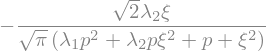

In [4]:
# Eqs. (A1)-(A2) of Christov (2015), and Eq. (3.5) of Aksel et al. (2006) in the Laplace domain
t = sp.Symbol('t', real=True)   # not positive=True, otherwise SymPy sets DiracDelta(t) = 0
p, y, xi = sp.symbols('p y xi', positive=True)
lambda_1, lambda_2 = sp.symbols('lambda_1 lambda_2', positive=True)
m2 = (1 + lambda_1*p)*p/(1 + lambda_2*p)
ubar = p/(p**2 + 1)*sp.exp(-y*sp.sqrt(m2))
display((sp.simplify(m2*ubar - ubar.diff(y, 2)), sp.simplify(ubar.subs(y, 0) - p/(p**2 + 1))))

# right-hand side divided by sqrt(2/pi) xi: plate velocity plus lambda_2 times its derivative
rhs_correct = sp.laplace_transform(sp.cos(t) + lambda_2*(sp.DiracDelta(t) - sp.sin(t)), t, p, noconds=True)
rhs_wrong = sp.laplace_transform(sp.cos(t) - lambda_2*sp.sin(t), t, p, noconds=True)   # Eq. (3.5): no delta(t)
modes = lambda_1*p**2 + (1 + lambda_2*xi**2)*p + xi**2
W_correct = sp.sqrt(2/sp.pi)*xi*rhs_correct/modes
W_wrong = sp.sqrt(2/sp.pi)*xi*rhs_wrong/modes
# the Fourier sine transform of Eq. (A2) is sqrt(2/pi) xi/(xi^2 + m^2) times the plate's transform
fst_ubar = sp.sqrt(2/sp.pi)*xi/(xi**2 + m2)*p/(p**2 + 1)
display(sp.simplify(W_correct - fst_ubar), sp.factor(sp.simplify(W_wrong - fst_ubar)))

So Eq. (3.5) is right once $\sqrt{2/\pi}\,\lambda_2\xi\,\delta(t)$ is restored; the nonzero output above is the transform of the response to that missing term. Since the equation is linear, the correct solution is Eq. (3.10) plus the response to that impulse,
$$
    u(y,t) = u_{(3.10)}(y,t) + \frac{2}{\pi}\lambda_2\int_0^\infty \xi\,G(\xi,t)\sin(y\xi)\,\mathrm{d}\xi,\qquad G(\xi,t) = \frac{\mathrm{e}^{r_1t}-\mathrm{e}^{r_2t}}{\lambda_1(r_1-r_2)},
$$
where, from Eq. (3.8) of Aksel _et al._ (2006),
$$
    r_{1,2} = \frac{-(1+\lambda_2\xi^2) \pm \beta}{2\lambda_1},
$$
so that $G(\xi,t)$ also takes three forms, with $\sinh$, its $\beta \to 0$ limit, and $\sin$, on the same intervals as $\Phi(\xi,t)$. This representation is shown here; Christov (2015) gives the solution only in the Laplace domain and calls the expressions for its inverse "lengthy" (p. 1652). As $\xi\to\infty$, $\lambda_2\xi G(\xi,t)\to \mathrm{e}^{-t/\lambda_2}/\xi$, which cancels the slowly decaying tail of the $\Phi(\xi,t)$ integral in Eq. (3.10). The code combines the two into one integrand.

In [5]:
# Eq. (A2) of Christov (2015) inverted as a Fourier sine integral: correct solution
def transient_integrand(xi, t, lam1, lam2):
    """The Phi integrand of Eq. (3.10) of Aksel et al. (2006) minus lam2 xi G(xi,t), the response to delta(t)."""
    ec, es = damped_modes(xi, t, lam1, lam2)
    G = 2*es   # G(xi,t) = (exp(r1 t) - exp(r2 t))/(lam1 (r1 - r2))
    return damped_Phi(xi, t, lam1, lam2) - lam2*xi*G

def unsteadyv(y, t, lam1, lam2):
    """Correct solution: inverse of Eq. (A2) of Christov (2015), at one point y."""
    if y == 0:
        return np.cos(t)
    edges = breakpoints(lam1, lam2)
    I_C = fourier_sine(lambda xi: C_coef(xi, lam1, lam2), y, edges)
    I_B = fourier_sine(lambda xi: B_coef(xi, lam1, lam2), y, edges)
    I_T = fourier_sine(lambda xi: transient_integrand(xi, t, lam1, lam2), y, edges)
    return np.cos(t) - 2/np.pi*np.cos(t)*I_C + 2/np.pi*np.sin(t)*I_B - 2/np.pi*I_T

As $t\to\infty$, only the oscillation at the plate's frequency is left: Eq. (41) of Hopkins & de Bruyn (2014),
$$
    u_r(y,t) = \exp\left[-k\cos\left(\frac{\phi}{2}\right)y\right]\cos\left[t-k\sin\left(\frac{\phi}{2}\right)y\right],
$$
with $k = [(1+\lambda_1^2)^{1/2}/(1+\lambda_2^2)^{1/2}]^{1/2}$ from their Eq. (39) at $B = 1$, and $\phi = \arctan[(1+\lambda_1\lambda_2)/(\lambda_2-\lambda_1)]$ from their Eq. (35), taken in $[0,\pi]$. Hopkins & de Bruyn (2014) call it the "steady-state velocity field"; item 1 of Christov (2015) calls it the late-time (post-transient) field, since it is periodic, not steady. The corrections of item 7 concern the stresses in Eqs. (22)&ndash;(23) and do not change Eq. (41). The same field is the "steady-state solution", Eqs. (3.14)&ndash;(3.15), of Aksel _et al._ (2006). The next cell checks that the two agree, which should print a difference at round-off level.

In [6]:
# Eqs. (35), (39) and (41) of Hopkins & de Bruyn (2014), B = 1: late-time solution
def late_hdb_41(y, t, lam1, lam2):
    """Late-time solution, Eq. (41) of Hopkins & de Bruyn (2014), B = 1."""
    k = ((1 + lam1**2)**0.5/(1 + lam2**2)**0.5)**0.5
    phi = np.arctan2(1 + lam1*lam2, lam2 - lam1)   # Eq. (35), in [0, pi]
    return np.exp(-k*np.cos(phi/2)*y)*np.cos(t - k*np.sin(phi/2)*y)

# Eqs. (3.14)-(3.15) of Aksel et al. (2006), omega = nu = V = 1
lam1, lam2 = 3.0, 2.0
m = np.sqrt((np.sqrt((1 + lam2**2)*(1 + lam1**2)) + lam2 - lam1)/(2*(1 + lam2**2)))
n = np.sqrt((np.sqrt((1 + lam2**2)*(1 + lam1**2)) - lam2 + lam1)/(2*(1 + lam2**2)))
y_check = np.linspace(0, 10, 101)
print(f'max|Eq. (41) - Eq. (3.14)| = {np.abs(late_hdb_41(y_check, 1.0, lam1, lam2) - np.exp(-m*y_check)*np.cos(1.0 - n*y_check)).max():.1e}')

max|Eq. (41) - Eq. (3.14)| = 1.1e-16


# AN INDEPENDENT CHECK

Three independent checks of the correct solution:

* Eq. (A2) inverted numerically by the algorithm of [de Hoog _et al._ (1982)](https://doi.org/10.1137/0903022), in [mpmath's `invertlaplace`](https://mpmath.org/doc/current/calculus/inverselaplace.html).
* The finite-difference scheme `startup_fd` for the Jeffreys (Oldroyd-B) fluid, written for the velocity $v$ and the polymer stress $S$,
\begin{align*}
    \mathrm{Re}\,\frac{\partial v}{\partial t_\mathrm{fd}} &= \frac{\partial S}{\partial x} + \kappa\frac{\partial^2 v}{\partial x^2},\qquad
    \frac{\partial S}{\partial t_\mathrm{fd}} + S = (1-\kappa)\,\frac{\partial v}{\partial x},
\end{align*}
in its own variables, $t_\mathrm{fd} = t/\lambda_1$, $\kappa = \lambda_2/\lambda_1$, $\mathrm{Re} = 1/\lambda_1$ and $x = L - y$, on a strip $0\le y\le L$ wide enough to stand in for the half-space. It uses [Crank&ndash;Nicolson](https://en.wikipedia.org/wiki/Crank%E2%80%93Nicolson_method) time stepping ([Crank & Nicolson, 1947](https://doi.org/10.1017/S0305004100023197)) with a Rannacher start-up ([Rannacher, 1984](https://doi.org/10.1007/BF01390130)); here the plate moves with velocity $H(t)\cos t$.
* The route that Christov (2015) proposes in Appendix A but does not carry out, the convolution theorem for the Laplace transform, that is, [Duhamel's principle](https://en.wikipedia.org/wiki/Duhamel%27s_principle), applied to the solution $u_1$ of Stokes' first problem for the same fluid, Eq. (7) of [C. I. Christov & P. M. Jordan (2009)](https://doi.org/10.1063/1.3126503) with $\beta = 0$, $\alpha = \lambda_1$ and $\alpha_t = \lambda_2$:
$$
    u(y,t) = \frac{\partial}{\partial t}\int_0^t u_1(y,t-s)\cos s\,\mathrm{d}s = u_1(y,t) - \int_0^t u_1(y,t-s)\sin s\,\mathrm{d}s.
$$

The next three cells define them, and the fourth prints the checks, with $\lambda_1 = 3$ and $\lambda_2 = 2$:

* the correct solution against de Hoog's inversion (about $10^{-10}$) and the Duhamel integral (quadrature level) at three times, and Eq. (3.10) against both, an error of order one;
* the value of Eq. (3.10) just off the wall, which should be $\cos t - \mathrm{e}^{-t/\lambda_2}$, not the plate velocity $\cos t$;
* the limit $\lambda_1 = \lambda_2$, where the equation of motion factors into
$$
    \left(1+\lambda_1\frac{\partial}{\partial t}\right)\left(\frac{\partial u}{\partial t} - \frac{\partial^2 u}{\partial y^2}\right) = 0,
$$
so that, with zero initial data, the correct solution should be the Newtonian one, the de Hoog inversion of Eq. (A2) at $\lambda_1 = \lambda_2 = 0$;
* the convergence of the finite differences, formally $O[(\Delta t)^2 + (\Delta y)^2]$, but first order in practice near the plate, because of the start-up jump.

Where a convergence table prints a number in parentheses, it is the estimated order of convergence, $\log_2$ of the ratio of successive errors.

In [7]:
# Eq. (A2) of Christov (2015): numerical inversion of the Laplace transform
def ubar_mp(p, y, lam1, lam2):
    """Eq. (A2) of Christov (2015), in mpmath arithmetic."""
    return p/(p**2 + 1)*mp.exp(-y*mp.sqrt((1 + lam1*p)*p/(1 + lam2*p)))

def dehoog_inverse(y, t, lam1, lam2):
    """Eq. (A2) inverted by mpmath's de Hoog algorithm, point by point in y (about 10 correct digits)."""
    u = np.zeros_like(y)
    for j in range(len(y)):
        u[j] = float(mp.invertlaplace(lambda p: ubar_mp(p, y[j], lam1, lam2), t, method='dehoog'))
    return u

In [8]:
# Finite differences for the problem of Christov (2015), Appendix A, with u(0,t) = H(t) cos t: startup_fd
def startup_fd(M=400, kappa=0.5, Re=1.0, tmax=1.0, L=1.0, dt=None, n_rannacher=4, n_iter=3, oscillation='', omega=0.0):
    """Start-up plane Couette flow of a Jeffreys fluid, (v, S) form; time scaled by lambda_1, plate at x = L."""
    # oscillation = 'cos' moves the plate with cos(omega t_fd) instead of 1
    dx = L/M
    if dt is None:
        dt = 0.5*dx*min(1.0, np.sqrt(Re))
    nsteps = int(np.ceil(tmax/dt))
    dt = tmax/nsteps
    x = np.linspace(0, L, M+1)
    v = np.zeros(M+1)
    S = np.zeros(M)
    v[-1] = 1.0
    # tridiagonal matrices for Crank-Nicolson (theta = 1/2) and backward Euler (theta = 1)
    r_cn = 0.5*kappa*dt/(Re*dx**2)
    ab_cn = np.zeros((3, M-1))
    ab_cn[0, 1:] = -r_cn
    ab_cn[1, :] = 1 + 2*r_cn
    ab_cn[2, :-1] = -r_cn
    r_be = kappa*dt/(Re*dx**2)
    ab_be = np.zeros((3, M-1))
    ab_be[0, 1:] = -r_be
    ab_be[1, :] = 1 + 2*r_be
    ab_be[2, :-1] = -r_be
    for n in range(nsteps):
        g = np.diff(v)/dx
        dS = -S + (1 - kappa)*g
        Sp = S + dt*dS
        if n < n_rannacher:
            r = r_be
            ab = ab_be
        else:
            r = r_cn
            ab = ab_cn
        vb = v.copy()
        if oscillation == 'cos':
            vb[-1] = np.cos(omega*(n + 1)*dt)
        # iterate the trapezoidal stress update and the implicit velocity update a few times
        for it in range(n_iter):
            Sm = 0.5*(S + Sp)
            rhs = v[1:-1] + dt/Re*np.diff(Sm)/dx
            if n >= n_rannacher:
                rhs = rhs + r*(v[2:] - 2*v[1:-1] + v[:-2])
            rhs[0] = rhs[0] + r*vb[0]
            rhs[-1] = rhs[-1] + r*vb[-1]
            vb[1:-1] = solve_banded((1, 1), ab, rhs)
            gp = np.diff(vb)/dx
            Sp = S + 0.5*dt*(dS + (-Sp + (1 - kappa)*gp))
        S = Sp
        v = vb
    return x, v

def fd_profile(t, lam1, lam2, M=1200, L=12.0):
    """u(y,t) from startup_fd, mapped back to y = L - x."""
    # t_fd = t/lam1, kappa = lam2/lam1, Re = 1/lam1, and the plate moves as cos(t) = cos(lam1 t_fd)
    x, v = startup_fd(M=M, kappa=lam2/lam1, Re=1/lam1, tmax=t/lam1, L=L, oscillation='cos', omega=lam1)
    return L - x, v

In [9]:
# Eqs. (4)-(8) of C. I. Christov & P. M. Jordan (2009), beta = 0, alpha = lam1, alpha_t = lam2: Stokes' first problem,
# then Duhamel's principle for the plate H(t) cos t
def Ubar_cj09(s, t, alpha, alpha_t):
    """U-bar of Eq. (4) of C. I. Christov & P. M. Jordan (2009) at beta = 0, both signs of f(s) of Eq. (5)."""
    f = (alpha_t**2*s**4 - 2*(2*alpha - alpha_t)*s**2 + 1)/(4*alpha**2)
    g = (1 + alpha_t*s**2)/(2*alpha)
    if abs(f) < 1e-14:
        # limit f -> 0 (at the breakpoints s_1, s_2)
        return s*np.exp(-g*t)*((1 + g*t)/s**2 - alpha_t*t/alpha)
    if f > 0:
        r = np.sqrt(f)
        # exp(-g t) cosh(r t) and exp(-g t) sinh(r t), written so that they do not overflow
        ec = 0.5*(np.exp((r - g)*t) + np.exp(-(r + g)*t))
        es = 0.5*(np.exp((r - g)*t) - np.exp(-(r + g)*t))
        return s*((r*ec + g*es)/(r*s**2) - alpha_t*es/(alpha*r))
    r = np.sqrt(-f)
    e = np.exp(-g*t)
    return s*(e*(r*np.cos(t*r) + g*np.sin(t*r))/(r*s**2) - alpha_t*e*np.sin(t*r)/(alpha*r))

def stokes1_cj09(y, t, lam1, lam2):
    """Eq. (7) of C. I. Christov & P. M. Jordan (2009), beta = 0, at one point y > 0."""
    if t <= 0:
        return 0.0
    # the breakpoints s_1, s_2 of their Eq. (8) are a, b of Aksel et al. (2006)
    return 1 - 2/np.pi*fourier_sine(lambda s: Ubar_cj09(s, t, lam1, lam2), y, breakpoints(lam1, lam2))

def duhamel(y, t, lam1, lam2):
    """u = u_1(y,t) - integral of u_1(y,t-s) sin(s) over (0, t): Duhamel's principle, at one point y > 0."""
    return stokes1_cj09(y, t, lam1, lam2) - quad(lambda s: stokes1_cj09(y, t - s, lam1, lam2)*np.sin(s), 0, t, limit=100)[0]

In [10]:
# Checks for Christov (2015)
lam1, lam2 = 3.0, 2.0
y = np.linspace(0.05, 6, 20)
y_duhamel = np.array([0.2, 1.0, 3.0])   # the nested quadrature is slow, so only three points

print(f'CORRECT SOLUTION VERSUS INDEPENDENT SOLUTIONS, lam1 = {lam1}, lam2 = {lam2}, max over 0.05 <= y <= 6')
for t in [np.pi/2, np.pi, 7*np.pi/2]:
    u_correct = profile(unsteadyv, y, t, lam1, lam2)
    u_dehoog = dehoog_inverse(y, t, lam1, lam2)
    u_wrong = profile(wrong_aksel_310, y, t, lam1, lam2)
    e_duhamel = np.abs(profile(unsteadyv, y_duhamel, t, lam1, lam2) - profile(duhamel, y_duhamel, t, lam1, lam2)).max()
    print(f'  t = {t:.4f}: de Hoog {np.abs(u_correct - u_dehoog).max():.1e}, Duhamel {e_duhamel:.1e}, '
          f'wrong Eq. (3.10) {np.abs(u_wrong - u_dehoog).max():.2f}')
    assert np.abs(u_correct - u_dehoog).max() < 1e-6   # a regression guard: the notebook stops here if a future edit breaks the agreement

print('\nEQ. (3.10) AT y = 1e-4 VERSUS cos t - exp(-t/lam2)')
for t in [np.pi/2, np.pi, 7*np.pi/2]:
    print(f'  t = {t:.4f}: Eq. (3.10) = {wrong_aksel_310(1e-4, t, lam1, lam2):+.4f}, '
          f'cos t - exp(-t/lam2) = {np.cos(t) - np.exp(-t/lam2):+.4f}, correct = {unsteadyv(1e-4, t, lam1, lam2):+.4f}')

print('\nLIMIT lam1 = lam2 (should be the Newtonian solution), t = 2, max over 0.05 <= y <= 6')
u_newtonian = dehoog_inverse(y, 2.0, 0.0, 0.0)
for lam in [0.5, 2.0]:
    print(f'  lam1 = lam2 = {lam}: correct {np.abs(profile(unsteadyv, y, 2.0, lam, lam) - u_newtonian).max():.1e}, '
          f'wrong Eq. (3.10) {np.abs(profile(wrong_aksel_310, y, 2.0, lam, lam) - u_newtonian).max():.2f}')

t = np.pi
u_dehoog = dehoog_inverse(y, t, lam1, lam2)
print(f'\nCONVERGENCE OF THE FINITE DIFFERENCES AGAINST DE HOOG, t = {t:.4f}, L = 12 (dt refined with dy)')
print('  grid: max error (estimated order of convergence)')
# the estimated order of convergence is log2 of the ratio of successive errors, since the grid is halved
previous = None
for M in [300, 600, 1200, 2400]:
    yf, uf = fd_profile(t, lam1, lam2, M)
    error = np.abs(np.interp(y, yf[::-1], uf[::-1]) - u_dehoog).max()
    if previous is None:
        print(f'  M = {M:4d}: {error:.1e}')
    else:
        print(f'  M = {M:4d}: {error:.1e} ({np.log2(previous/error):.2f})')
    previous = error

CORRECT SOLUTION VERSUS INDEPENDENT SOLUTIONS, lam1 = 3.0, lam2 = 2.0, max over 0.05 <= y <= 6


  t = 1.5708: de Hoog 7.7e-10, Duhamel 3.4e-11, wrong Eq. (3.10) 0.46


  t = 3.1416: de Hoog 4.7e-11, Duhamel 2.7e-11, wrong Eq. (3.10) 0.26


  t = 10.9956: de Hoog 6.5e-11, Duhamel 5.6e-11, wrong Eq. (3.10) 0.06

EQ. (3.10) AT y = 1e-4 VERSUS cos t - exp(-t/lam2)
  t = 1.5708: Eq. (3.10) = -0.4559, cos t - exp(-t/lam2) = -0.4559, correct = +0.0001
  t = 3.1416: Eq. (3.10) = -1.2078, cos t - exp(-t/lam2) = -1.2079, correct = -0.9999
  t = 10.9956: Eq. (3.10) = -0.0042, cos t - exp(-t/lam2) = -0.0041, correct = -0.0001

LIMIT lam1 = lam2 (should be the Newtonian solution), t = 2, max over 0.05 <= y <= 6


  lam1 = lam2 = 0.5: correct 2.4e-11, wrong Eq. (3.10) 0.08
  lam1 = lam2 = 2.0: correct 2.4e-11, wrong Eq. (3.10) 0.37



CONVERGENCE OF THE FINITE DIFFERENCES AGAINST DE HOOG, t = 3.1416, L = 12 (dt refined with dy)
  grid: max error (estimated order of convergence)
  M =  300: 5.8e-04
  M =  600: 2.7e-04 (1.10)
  M = 1200: 1.2e-04 (1.15)


  M = 2400: 5.4e-05 (1.16)


# EARLY- AND LATE-TIME ASYMPTOTICS

Small $t$ corresponds to large $p$ ([Bargmann _et al._, 2008](https://doi.org/10.1016/j.physleta.2008.04.010), Sect. 2.2). Expanding the exponent of Eq. (A2) for $p\to\infty$ gives Eqs. (A3)&ndash;(A4) of Christov (2015),
$$
    \bar{u}(y,p) = \left[\frac{1}{p} + O\left(\frac{1}{p^3}\right)\right]\exp\left(-y\chi\sqrt{p}\right)\left[1 + \frac{y\chi\Lambda}{2\sqrt{p}} + O\left(\frac{1}{p}\right)\right],
$$
with $\chi = \sqrt{\lambda_1/\lambda_2}$ and $\Lambda = (\lambda_1-\lambda_2)/(\lambda_1\lambda_2)$. Inverting term by term gives Eq. (A5),
$$
    u(y,t) \simeq \mathrm{erfc}\left(\frac{y\chi}{2\sqrt{t}}\right) + \frac{y\chi\Lambda}{2}\left[2\sqrt{\frac{t}{\pi}}\exp\left(-\frac{y^2\chi^2}{4t}\right) - y\chi\,\mathrm{erfc}\left(\frac{y\chi}{2\sqrt{t}}\right)\right].
$$
Eq. (A5) needs $\lambda_2 > 0$; for a Maxwell fluid ($\lambda_2 = 0$), the start-up jump travels into the fluid as an elastic wave instead. The next cell does both steps with SymPy. It prints the coefficients of $\sqrt{p}$ and $1/\sqrt{p}$ in the expanded exponent, each next to $\chi$ and $-\chi\Lambda/2$, then the Laplace transforms of the two terms of Eq. (A5), which should be $\mathrm{e}^{-a\sqrt{p}}/p$ and $\mathrm{e}^{-a\sqrt{p}}/p^{3/2}$, with $a = y\chi$.

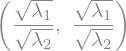

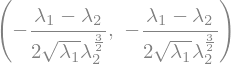

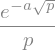

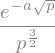

In [11]:
# Eqs. (A3)-(A5) of Christov (2015): large-p expansion and term-by-term inversion
q = sp.Symbol('q', positive=True)   # q = 1/sqrt(p), small when p is large
chi = sp.sqrt(lambda_1/lambda_2)
Lam = (lambda_1 - lambda_2)/(lambda_1*lambda_2)
exponent = sp.series(sp.sqrt(m2).subs(p, 1/q**2), q, 0, 2).removeO()
# coefficients of sqrt(p) and of 1/sqrt(p) in the exponent, each next to chi and -chi Lambda/2 of Eq. (A3)
display((sp.factor(exponent.coeff(q, -1)), chi), (sp.factor(exponent.coeff(q, 1)), sp.factor(-chi*Lam/2)))

tp, a = sp.symbols('t a', positive=True)   # a = y chi
term0 = sp.erfc(a/(2*sp.sqrt(tp)))
term1 = 2*sp.sqrt(tp/sp.pi)*sp.exp(-a**2/(4*tp)) - a*sp.erfc(a/(2*sp.sqrt(tp)))
# Laplace transforms of the two terms of Eq. (A5)
display(sp.simplify(sp.laplace_transform(term0, tp, p, noconds=True).rewrite(sp.exp)),
        sp.simplify(sp.laplace_transform(term1, tp, p, noconds=True).rewrite(sp.exp)))

def early_A5(y, t, lam1, lam2):
    """Early-time asymptotics, Eq. (A5) of Christov (2015)."""
    chi = np.sqrt(lam1/lam2)
    Lam = (lam1 - lam2)/(lam1*lam2)
    z = y*chi/(2*np.sqrt(t))
    return erfc(z) + y*chi*Lam/2*(2*np.sqrt(t/np.pi)*np.exp(-z**2) - y*chi*erfc(z))

Large $t$ corresponds to small $p$. The poles of Eq. (A2) at $p = \pm\mathrm{i}$ give Eq. (41); the rest, the transient $u - u_r$, comes from the branch point at $p = 0$. For $p\to0$,
$$
    \bar{u}(y,p) = p - yp^{3/2} + O(p^2).
$$
Integer powers of $p$ invert to derivatives of $\delta(t)$, which vanish for $t > 0$, so the first term that counts is $-yp^{3/2}$, which inverts to
$$
    u(y,t) - u_r(y,t) \simeq -\frac{3y}{4\sqrt{\pi}}\,t^{-5/2}\qquad (t\to\infty,\ y\ \text{fixed}).
$$
This tail is shown here; it is not stated in Christov (2015). The transient decays algebraically, like $t^{-5/2}$, whatever $\lambda_1$ and $\lambda_2$ are. Viscoelastic effects decay before the start-up transient. Hopkins & de Bruyn (2014, p. 535) take their "steady state" to hold for $t \gg \lambda_1$; the tail shows that no material time sets the end of the transient.

The next cell finds the small-$p$ expansion and the inverse of $p^{3/2}$ with SymPy. It then defines $\bar{u} - \bar{u}_r$, Eq. (A2) minus the transform of Eq. (41), which has no poles at $p = \pm\mathrm{i}$ and so can be inverted numerically at large $t$.

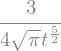

In [12]:
# Large-t tail of the transient: small-p expansion of Eq. (A2) of Christov (2015)
display(sp.series(ubar, p, 0, 2), sp.inverse_laplace_transform(p**sp.Rational(3, 2), p, tp))

def transient_hat(p, y, lam1, lam2):
    """Eq. (A2) minus the Laplace transform of Eq. (41) of Hopkins & de Bruyn (2014), in mpmath arithmetic."""
    # Eq. (41) is the real part of f(y) exp(i t), with f(y) of their Eq. (37) at B = 1
    f = mp.exp(-y*mp.sqrt((1 + lam1*1j)*1j/(1 + lam2*1j)))
    return p/(p**2 + 1)*mp.exp(-y*mp.sqrt((1 + lam1*p)*p/(1 + lam2*p))) - 0.5*(f/(p - 1j) + mp.conj(f)/(p + 1j))

def transient_dehoog(y, t, lam1, lam2):
    """u - u_r at one point y, by de Hoog's inversion of transient_hat."""
    return float(mp.re(mp.invertlaplace(lambda p: transient_hat(p, y, lam1, lam2), t, method='dehoog')))

The next cell measures both asymptotics against the correct solution, with $\lambda_1 = 3$, $\lambda_2 = 2$ (the values of Fig. 1 of Aksel _et al._ (2006)). For early times, it prints the maximum error over $0 < y < 6\sqrt{t}/\chi$ of Eq. (A5) and of its leading term $\mathrm{erfc}[y\chi/(2\sqrt{t})]$ alone; as $t$ doubles, the estimated order should be about 2 for Eq. (A5) and about 1 for erfc alone. For late times, it prints the transient at $y = 1$ divided by the tail $-3y\,t^{-5/2}/(4\sqrt{\pi})$, which should tend to 1. Where a table prints a number in parentheses, it is the estimated order of convergence, $\log_2$ of the ratio of successive errors.

The two figures after the table are shown here and are in neither paper. The first shows both asymptotics on log-log axes; the second follows the velocity in time at one point near the plate, $y = 0.3$. At early times, Eq. (A5) and its erfc term are drawn for $t \le 0.1$, where they are accurate at this $y$; Eq. (3.10) stays near zero, because the plate it solves for starts from rest. Over three periods, the correct solution settles onto Eq. (41) within about one period, while Eq. (3.10) lags behind it over the first two: the error is confined to the start-up.

In [13]:
# Eq. (A5) of Christov (2015) and the t^(-5/2) tail versus the correct solution
lam1, lam2 = 3.0, 2.0
chi = np.sqrt(lam1/lam2)
t_early = [0.0025, 0.005, 0.01, 0.02, 0.04, 0.08]
err_A5 = []
err_erfc = []
print('EARLY TIMES: max error over 0 < y < 6 sqrt(t)/chi')
print('  t: max error (estimated order of convergence), Eq. (A5), then erfc alone')
# the estimated order of convergence is log2 of the ratio of successive errors, since t is doubled
for i in range(len(t_early)):
    t = t_early[i]
    y = np.linspace(0, 6*np.sqrt(t)/chi, 25)[1:]
    u = profile(unsteadyv, y, t, lam1, lam2)
    err_A5.append(np.abs(u - early_A5(y, t, lam1, lam2)).max())
    err_erfc.append(np.abs(u - erfc(y*chi/(2*np.sqrt(t)))).max())
    if i == 0:
        print(f'  t = {t:.4f}: {err_A5[i]:.1e}, {err_erfc[i]:.1e}')
    else:
        print(f'  t = {t:.4f}: {err_A5[i]:.1e} ({np.log2(err_A5[i]/err_A5[i-1]):.2f}), '
              f'{err_erfc[i]:.1e} ({np.log2(err_erfc[i]/err_erfc[i-1]):.2f})')

t_late = [10.0, 20.0, 40.0, 80.0, 160.0, 320.0]
transient = []
print('\nLATE TIMES: (u - u_r)/(-3 y t^(-5/2)/(4 sqrt(pi))) at y = 1')
for t in t_late:
    transient.append(transient_dehoog(1.0, t, lam1, lam2))
    print(f'  t = {t:5.0f}: {transient[-1]/(-3/(4*np.sqrt(np.pi))*t**-2.5):.4f}')

EARLY TIMES: max error over 0 < y < 6 sqrt(t)/chi
  t: max error (estimated order of convergence), Eq. (A5), then erfc alone
  t = 0.0025: 2.2e-06, 8.3e-05
  t = 0.0050: 8.6e-06 (2.00), 1.6e-04 (0.99)
  t = 0.0100: 3.5e-05 (2.00), 3.2e-04 (0.98)


  t = 0.0200: 1.4e-04 (2.00), 6.2e-04 (0.95)
  t = 0.0400: 5.5e-04 (2.00), 1.2e-03 (0.90)
  t = 0.0800: 2.2e-03 (2.00), 2.0e-03 (0.79)

LATE TIMES: (u - u_r)/(-3 y t^(-5/2)/(4 sqrt(pi))) at y = 1
  t =    10: 0.8585
  t =    20: 0.8625


  t =    40: 0.9466
  t =    80: 0.9765
  t =   160: 0.9889
  t =   320: 0.9946


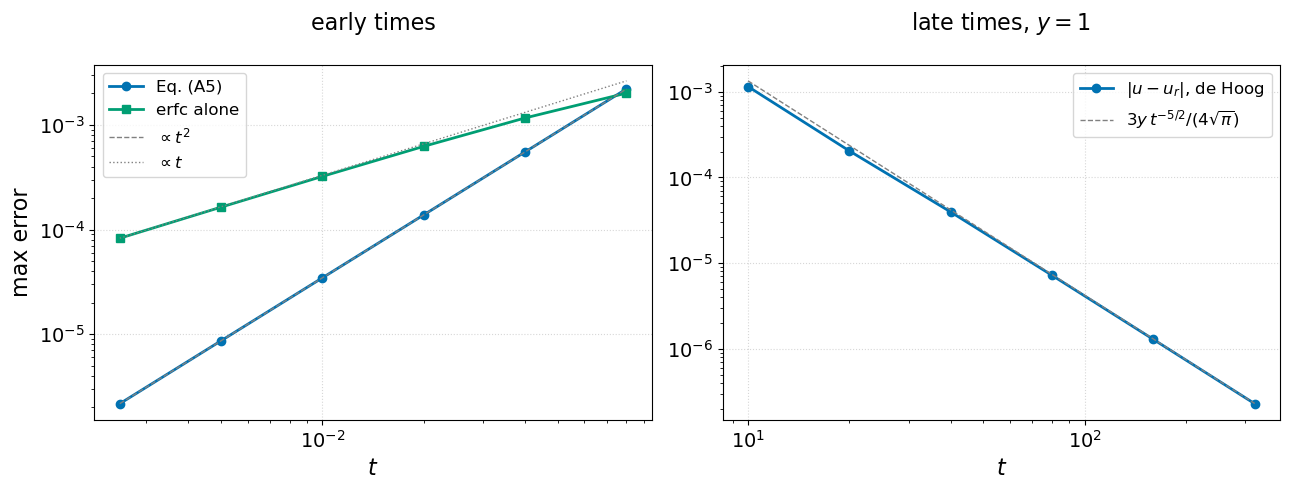

In [14]:
# Eq. (A5) of Christov (2015) and the t^(-5/2) tail: errors and transient on log-log axes (new figure)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), tight_layout=True)
t_early = np.array(t_early)
ax1.loglog(t_early, err_A5, 'o-', color='#0072B2', linewidth=2, label='Eq. (A5)')
ax1.loglog(t_early, err_erfc, 's-', color='#009E73', linewidth=2, label='erfc alone')
ax1.loglog(t_early, err_A5[0]*(t_early/t_early[0])**2, color='gray', linewidth=1, linestyle='dashed', label='$\\propto t^2$')
ax1.loglog(t_early, err_erfc[0]*(t_early/t_early[0]), color='gray', linewidth=1, linestyle='dotted', label='$\\propto t$')
ax1.set_xlabel('$t$')
ax1.set_ylabel('max error')
ax1.set_title('early times')
ax1.grid(alpha=0.5, linestyle='dotted')
ax1.legend(loc='upper left', fontsize=12)

t_late = np.array(t_late)
ax2.loglog(t_late, np.abs(transient), 'o-', color='#0072B2', linewidth=2, label='$|u - u_r|$, de Hoog')
ax2.loglog(t_late, 3/(4*np.sqrt(np.pi))*t_late**-2.5, color='gray', linewidth=1, linestyle='dashed',
           label='$3y\\,t^{-5/2}/(4\\sqrt{\\pi})$')
ax2.set_xlabel('$t$')
ax2.set_title('late times, $y = 1$')
ax2.grid(alpha=0.5, linestyle='dotted')
ax2.legend(loc='upper right', fontsize=12)
#fig.savefig('../figures/christov_2015_asymptotics.png', dpi=200, bbox_inches='tight')
plt.show()

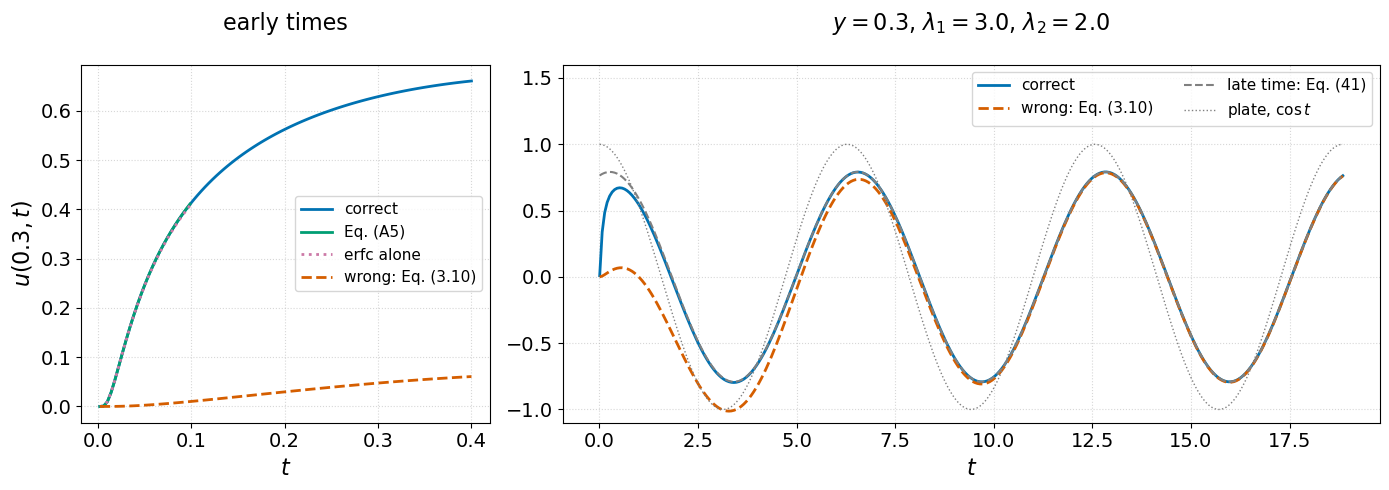

In [15]:
# u(0.3, t): correct solution, Eqs. (A5) and (41), and Eq. (3.10) of Aksel et al. (2006) in time (new figure)
lam1, lam2, y0 = 3.0, 2.0, 0.3
chi = np.sqrt(lam1/lam2)
t_short = np.linspace(0.002, 0.4, 100)
t_long = np.linspace(0.01, 6*np.pi, 300)
u_short = np.zeros_like(t_short)
u_short_wrong = np.zeros_like(t_short)
for i in range(len(t_short)):
    u_short[i] = unsteadyv(y0, t_short[i], lam1, lam2)
    u_short_wrong[i] = wrong_aksel_310(y0, t_short[i], lam1, lam2)
u_long = np.zeros_like(t_long)
u_long_wrong = np.zeros_like(t_long)
for i in range(len(t_long)):
    u_long[i] = unsteadyv(y0, t_long[i], lam1, lam2)
    u_long_wrong[i] = wrong_aksel_310(y0, t_long[i], lam1, lam2)
t_asym = t_short[t_short <= 0.1]   # where Eq. (A5) is accurate at this y

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), tight_layout=True, gridspec_kw={'width_ratios': [1, 2]})
ax1.plot(t_short, u_short, color='#0072B2', linewidth=2, label='correct')
ax1.plot(t_asym, early_A5(y0, t_asym, lam1, lam2), color='#009E73', linewidth=2, label='Eq. (A5)')
ax1.plot(t_asym, erfc(y0*chi/(2*np.sqrt(t_asym))), color='#CC79A7', linewidth=2, linestyle='dotted', label='erfc alone')
ax1.plot(t_short, u_short_wrong, color='#D55E00', linewidth=2, linestyle='dashed', label='wrong: Eq. (3.10)')
ax1.set_xlabel('$t$')
ax1.set_ylabel(f'$u({y0},t)$')
ax1.set_title('early times')
ax1.grid(alpha=0.5, linestyle='dotted')
ax1.legend(loc='center right', fontsize=11)

ax2.plot(t_long, u_long, color='#0072B2', linewidth=2, label='correct')
ax2.plot(t_long, u_long_wrong, color='#D55E00', linewidth=2, linestyle='dashed', label='wrong: Eq. (3.10)')
ax2.plot(t_long, late_hdb_41(y0, t_long, lam1, lam2), color='gray', linewidth=1.5, linestyle='dashed', label='late time: Eq. (41)')
ax2.plot(t_long, np.cos(t_long), color='gray', linewidth=1, linestyle='dotted', label='plate, $\\cos t$')
ax2.set_xlabel('$t$')
ax2.set_ylim(-1.1, 1.6)
ax2.set_title(f'$y = {y0}$, $\\lambda_1 = {lam1}$, $\\lambda_2 = {lam2}$')
ax2.grid(alpha=0.5, linestyle='dotted')
ax2.legend(loc='upper right', ncol=2, fontsize=11)
#fig.savefig('../figures/christov_2015_time_series.png', dpi=200, bbox_inches='tight')
plt.show()

# THE PAPERS' FIGURES

Christov (2015) has no figure. This is Fig. 1 of Hopkins & de Bruyn (2014): the late-time profile, Eq. (41), at $t = 0$ with $B = 1$, for (a) $\lambda_1 = \lambda_2 = 0$, Newtonian; (b) $\lambda_1 = 1$, $\lambda_2 = 0$, Maxwell; (c) $\lambda_1 = 0.1$, $\lambda_2 = 10$, which they call unphysical; and (d) $\lambda_1 = 10$, $\lambda_2 = 0.1$.

The true velocity at $t = 0$ is zero, not Eq. (41). The figure after it, shown here and in neither paper, places the start-up solution at $t = 2\pi$, $4\pi$ and $8\pi$ (after one, two and four periods, when Eq. (41) repeats its $t = 0$ profile) on each panel. Each curve is Eq. (41) plus the de Hoog inversion of $\bar{u} - \bar{u}_r$. The larger $\lambda_1 - \lambda_2$, the more periods it takes to reach the profile drawn by Hopkins & de Bruyn (2014): panel (d) is still far from it after one period.

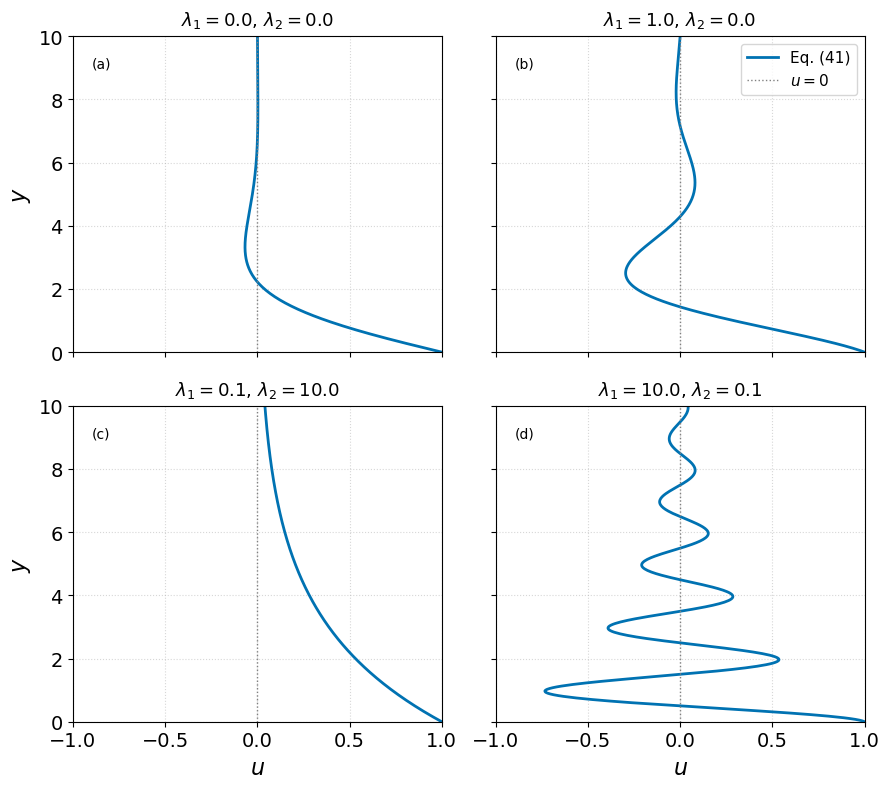

In [16]:
# Fig. 1 of Hopkins & de Bruyn (2014): Eq. (41) at t = 0, B = 1
panels = [['(a)', 0.0, 0.0], ['(b)', 1.0, 0.0], ['(c)', 0.1, 10.0], ['(d)', 10.0, 0.1]]
y = np.linspace(0, 10, 400)

fig, axes = plt.subplots(2, 2, figsize=(9, 8), sharex=True, sharey=True, tight_layout=True)
for i in range(4):
    ax = axes[i//2, i%2]
    label, lam1, lam2 = panels[i]
    ax.plot(late_hdb_41(y, 0.0, lam1, lam2), y, color='#0072B2', linewidth=2, label='Eq. (41)')
    ax.axvline(0, color='gray', linewidth=1, linestyle='dotted', label='$u = 0$')
    ax.text(-0.9, 9.0, label)
    ax.set_title(rf'$\lambda_1 = {lam1}$, $\lambda_2 = {lam2}$', fontsize=13, pad=8)
    ax.set_xlim(-1, 1)
    ax.set_ylim(0, 10)
    ax.grid(alpha=0.5, linestyle='dotted')
for i in range(2):
    axes[1, i].set_xlabel('$u$')
    axes[i, 0].set_ylabel('$y$')
axes[0, 1].legend(loc='upper right', fontsize=11)
os.makedirs('../figures', exist_ok=True)
fig.savefig('../figures/hopkins_de_bruyn_2014_fig1.png', dpi=200, bbox_inches='tight')

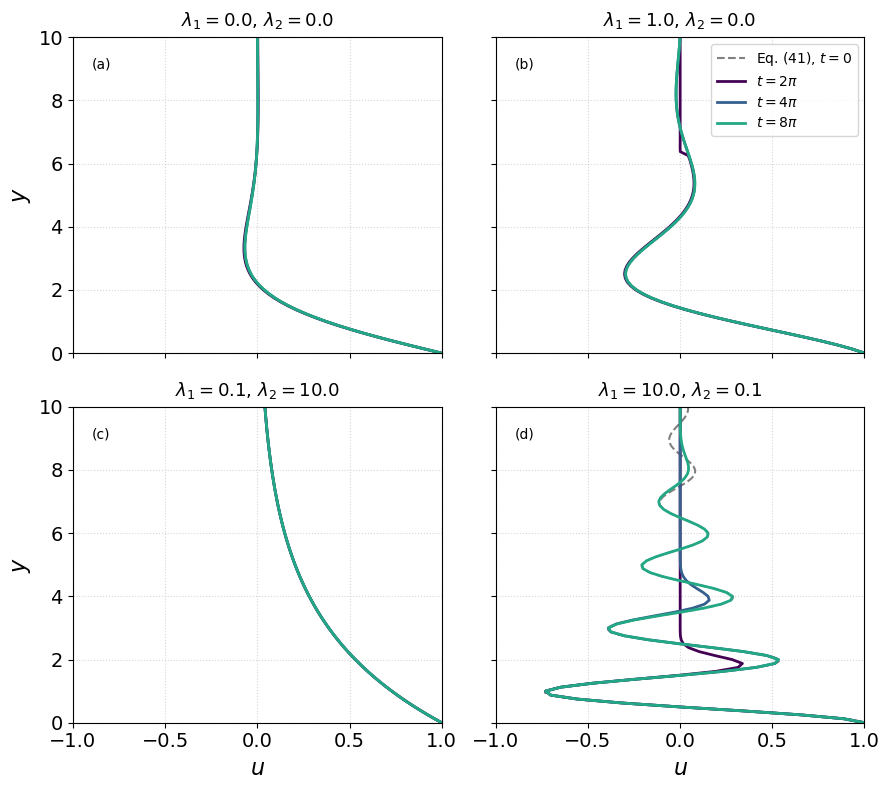

In [17]:
# Fig. 1 of Hopkins & de Bruyn (2014) with the start-up solution after one, two and four periods (new figure)
cmap = colormaps['viridis']
times = [2*np.pi, 4*np.pi, 8*np.pi]
time_labels = ['$t = 2\\pi$', '$t = 4\\pi$', '$t = 8\\pi$']
y_fine = np.linspace(0, 10, 400)
y_exact = np.linspace(0, 10, 81)   # de Hoog is point by point, so a coarser grid

fig, axes = plt.subplots(2, 2, figsize=(9, 8), sharex=True, sharey=True, tight_layout=True)
for i in range(4):
    ax = axes[i//2, i%2]
    label, lam1, lam2 = panels[i]
    ax.plot(late_hdb_41(y_fine, 0.0, lam1, lam2), y_fine, color='gray', linewidth=1.5, linestyle='dashed',
            label='Eq. (41), $t = 0$')
    for k in range(len(times)):
        u = late_hdb_41(y_exact, times[k], lam1, lam2)
        for j in range(len(y_exact)):
            if y_exact[j] > 0:
                u[j] = u[j] + transient_dehoog(y_exact[j], times[k], lam1, lam2)
        ax.plot(u, y_exact, color=cmap(0.6*np.log(times[k]/times[0])/np.log(times[-1]/times[0])), linewidth=2,
                label=time_labels[k])
    ax.text(-0.9, 9.0, label)
    ax.set_title(rf'$\lambda_1 = {lam1}$, $\lambda_2 = {lam2}$', fontsize=13, pad=8)
    ax.set_xlim(-1, 1)
    ax.set_ylim(0, 10)
    ax.grid(alpha=0.5, linestyle='dotted')
for i in range(2):
    axes[1, i].set_xlabel('$u$')
    axes[i, 0].set_ylabel('$y$')
axes[0, 1].legend(loc='upper right', fontsize=10)
#fig.savefig('../figures/christov_2015_hdb_fig1_periods.png', dpi=200, bbox_inches='tight')
plt.show()

This is Fig. 1 of Aksel _et al._ (2006), in the notation here: $u$ versus $y$ for $\lambda_1 = 3$ and $\lambda_2 = 2$ at $t = \pi/2, \pi, \dots, 7\pi/2$, with Eq. (3.10) dashed and the correct solution added solid. Their eighth panel, a 3D plot of the same solution, is left out. On the published grid, which starts at the wall, Eq. (3.10) jumps there from $\cos t$ to $\cos t - \mathrm{e}^{-t/\lambda_2}$.

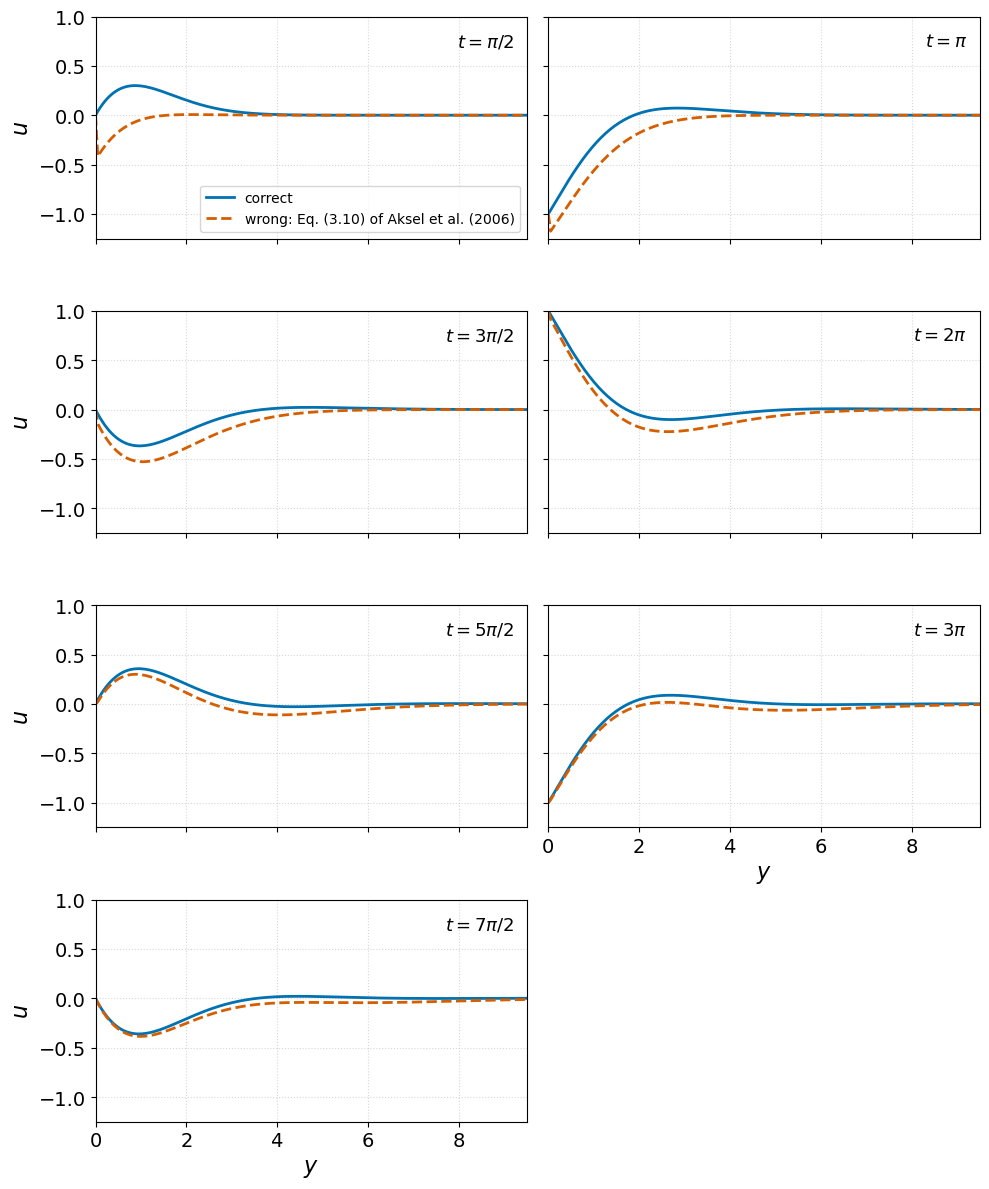

In [18]:
# Fig. 1 of Aksel, Fetecau & Scholle (2006), lam1 = 3, lam2 = 2, with the correct solution added
lam1, lam2 = 3.0, 2.0
times = [np.pi/2, np.pi, 3*np.pi/2, 2*np.pi, 5*np.pi/2, 3*np.pi, 7*np.pi/2]
time_labels = ['$t = \\pi/2$', '$t = \\pi$', '$t = 3\\pi/2$', '$t = 2\\pi$',
               '$t = 5\\pi/2$', '$t = 3\\pi$', '$t = 7\\pi/2$']
y = np.linspace(0, 9.5, 191)

fig, axes = plt.subplots(4, 2, figsize=(10, 12), sharex=True, sharey=True, tight_layout=True)
for i in range(len(times)):
    ax = axes[i//2, i%2]
    ax.plot(y, profile(unsteadyv, y, times[i], lam1, lam2), color='#0072B2', linewidth=2, label='correct')
    ax.plot(y, profile(wrong_aksel_310, y, times[i], lam1, lam2), color='#D55E00', linewidth=2, linestyle='dashed',
            label='wrong: Eq. (3.10) of Aksel et al. (2006)')
    ax.text(0.97, 0.93, time_labels[i], transform=ax.transAxes, ha='right', va='top', fontsize=13)
    ax.set_xlim(0, 9.5)
    ax.set_ylim(-1.25, 1)
    ax.grid(alpha=0.5, linestyle='dotted')
axes[3, 1].axis('off')   # the 3D panel of the paper is left out
axes[2, 1].xaxis.set_tick_params(labelbottom=True)
axes[3, 0].set_xlabel('$y$')
axes[2, 1].set_xlabel('$y$')
for i in range(4):
    axes[i, 0].set_ylabel('$u$')
axes[0, 0].legend(loc='lower right', fontsize=10)
fig.savefig('../figures/aksel_fetecau_scholle_2006_fig1.png', dpi=200, bbox_inches='tight')

# EXPLORE IT YOURSELF

In [19]:
# Correct solution, Eq. (3.10) of Aksel et al. (2006) and Eq. (41) of Hopkins & de Bruyn (2014): interactive comparison
def plot_func(lam1, lam2, t):
    y = np.linspace(0, 6, 81)          # envelope grid, coarser than usual: each point costs three quadratures
    y_arrows = np.linspace(0, 6, 16)   # about 15 arrows, one at the wall
    u = profile(unsteadyv, y, t, lam1, lam2)
    # Eq. (3.10) is discontinuous at the wall, so it is drawn from the first grid point off it,
    # where it is already near its limit cos t - exp(-t/lam2), and not from its value at y = 0
    u_wrong = profile(wrong_aksel_310, y[1:], t, lam1, lam2)

    fig, ax = plt.subplots(tight_layout=True)
    ax.set_ylabel('$y$')
    ax.set_ylim(0, 6)
    ax.set_xlabel('$u$')
    ax.set_xlim(-1.3, 1.3)   # symmetric: the plate oscillates
    ax.plot(u, y, color='darkblue', linewidth=4, zorder=4, label=f'correct, $t={t:.3g}$')
    ax.quiver(0*y_arrows, y_arrows, np.interp(y_arrows, y, u), 0*y_arrows, scale=1., scale_units='xy', color='blue', zorder=3, clip_on=False)
    ax.plot(u_wrong, y[1:], color='#D55E00', linewidth=2, linestyle='dashed', zorder=4, label='wrong: Eq. (3.10)')
    ax.plot(late_hdb_41(y, t, lam1, lam2), y, color='gray', linewidth=1.5, linestyle='dashed', label='late time: Eq. (41)')
    ax.legend(loc='upper right')
    ax.grid(alpha=0.5, linestyle='dotted')
    plt.show()

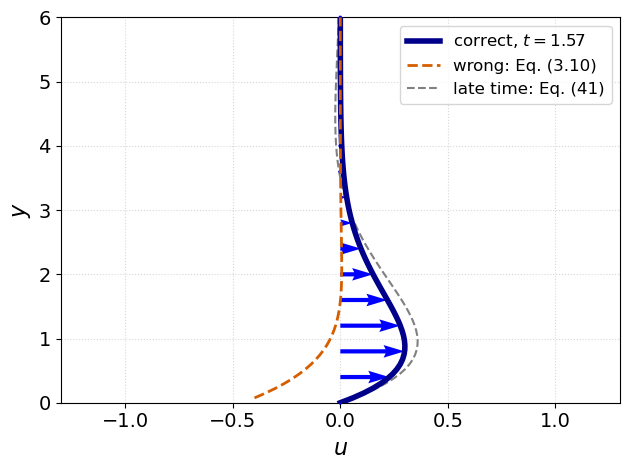

In [20]:
# Correct solution, Eq. (3.10) and Eq. (41): static plot at t = pi/2 (the interactive widget below is stripped in the GitHub preview)
plot_func(3.0, 2.0, np.pi/2)

In [21]:
# Correct solution, Eq. (3.10) and Eq. (41): interactive plot
interact(plot_func,
         lam1=widgets.FloatSlider(value=3.0, min=0.1, max=10.0, step=0.1, description='Relax., λ₁'),
         lam2=widgets.FloatSlider(value=2.0, min=0.05, max=5.0, step=0.05, description='Retard., λ₂'),
         t=widgets.FloatSlider(value=np.pi/2, min=0.05, max=4*np.pi, step=0.05, readout_format='.2f', description='Time, t'));

In [22]:
# Correct solution and Eq. (3.10) of Aksel et al. (2006): animation over two periods
lam1, lam2 = 3.0, 2.0
# number of animation frames, and the time of the first one, as `animate' computes it below
numframes = 40
tmax = 4*np.pi
# the first frame; the time steps uniformly, so that the frames sample the period evenly
t0 = tmax/numframes
y = np.linspace(0, 6, 61)          # envelope grid, coarser than usual: each point costs three quadratures
y_arrows = np.linspace(0, 6, 16)   # about 15 arrows, one at the wall
u = profile(unsteadyv, y, t0, lam1, lam2)

fig, ax = plt.subplots(tight_layout=True)
ax.set_ylabel('$y$')
ax.set_ylim(0, 6)
ax.set_xlabel('$u$')
ax.set_xlim(-1.3, 1.3)
ax.grid(alpha=0.5, linestyle='dotted')
plt.close()

line, = ax.plot(u, y, color='darkblue', linewidth=4, zorder=4, label='correct')
# Eq. (3.10) is discontinuous at the wall, so it is drawn from the first grid point off it
line_wrong, = ax.plot(profile(wrong_aksel_310, y[1:], t0, lam1, lam2), y[1:], color='#D55E00',
                      linewidth=2, linestyle='dashed', zorder=4, label='wrong: Eq. (3.10)')
quiv = ax.quiver(0*y_arrows, y_arrows, np.interp(y_arrows, y, u),
                 0*y_arrows, scale=1., scale_units='xy', color='blue', zorder=3, clip_on=False)
ax.legend(loc='upper right')

# animation function called sequentially by `FuncAnimation' below
def animate(i):
    # the i passed is the frame counter
    tstar = (i + 1)/numframes*tmax
    u = profile(unsteadyv, y, tstar, lam1, lam2)
    line.set_data(u, y)
    line_wrong.set_data(profile(wrong_aksel_310, y[1:], tstar, lam1, lam2), y[1:])
    quiv.set_UVC(np.interp(y_arrows, y, u), 0*y_arrows)
    line.set_label(f'correct, $t={tstar:.3g}$')
    legend = ax.legend(loc='upper right')
    return (line, line_wrong, quiv, legend)

anim = animation.FuncAnimation(fig, animate, frames=numframes, interval=150, blit=True, repeat=False)

In [23]:
# this is necessary to get the animation to work on Google's Colab
rc('animation', html='jshtml')
anim

In [24]:
# To save the animation, use something like
# anim.save('christov_2015_stokes2.mp4')

# WHAT PROBLEM DOES THE WRONG SOLUTION ACTUALLY SOLVE?

Dividing the transform of Eq. (3.5) by the correct one and multiplying by the plate's transform, $p/(p^2+1)$, gives the transform of the plate velocity for which Eq. (3.10) is exact. The next cell inverts it with SymPy; it should print $\cos t - \mathrm{e}^{-t/\lambda_2}$. So Eq. (3.10) of Aksel _et al._ (2006) is the exact solution for the plate velocity
$$
    u(0,t) = \left(\cos t - \mathrm{e}^{-t/\lambda_2}\right)H(t),
$$
a plate whose start-up jump is ramped on the retardation time $\lambda_2$. This identification is shown here; it is not stated in Christov (2015). It extends to this problem the ramped plate that [I. C. Christov & C. I. Christov (2010)](https://arxiv.org/abs/1003.2188) found for Stokes' first problem of a second-grade fluid.

The cell after it compares Eq. (3.10) with the de Hoog inversion of $\bar{u}(y,p)$ for that plate, which should agree to quadrature level. It then prints what the ramped plate does: it moves forward only until $\cos t = \mathrm{e}^{-t/\lambda_2}$, then backward, and at $t = \pi/2$ it moves backward with speed $\mathrm{e}^{-\pi/(2\lambda_2)}$. It also prints the minimum over $y$ of the correct solution at $t = \pi/2$, which should be zero to quadrature level: the correct velocity is nowhere negative there.

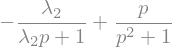

In [25]:
# Eq. (3.5) of Aksel et al. (2006) over the correct transform: the plate velocity that Eq. (3.10) solves
plate_wrong = sp.apart(sp.simplify(p/(p**2 + 1)*W_wrong/W_correct), p)
display(plate_wrong, sp.inverse_laplace_transform(plate_wrong, p, tp))

In [26]:
# Eq. (3.10) of Aksel et al. (2006) versus the solution for the plate velocity cos(t) - exp(-t/lam2)
def ubar_ramp_mp(p, y, lam1, lam2):
    """The transform of Eq. (A2) of Christov (2015), with p/(p^2 + 1) replaced by the ramped plate's transform."""
    return (p/(p**2 + 1) - 1/(p + 1/lam2))*mp.exp(-y*mp.sqrt((1 + lam1*p)*p/(1 + lam2*p)))

lam1, lam2 = 3.0, 2.0
y = np.linspace(0.05, 6, 20)
for t in [np.pi/2, np.pi, 7*np.pi/2]:
    u_ramp = np.zeros_like(y)
    for j in range(len(y)):
        u_ramp[j] = float(mp.invertlaplace(lambda p: ubar_ramp_mp(p, y[j], lam1, lam2), t, method='dehoog'))
    print(f't = {t:.4f}: max|Eq. (3.10) - ramped-plate solution| = {np.abs(profile(wrong_aksel_310, y, t, lam1, lam2) - u_ramp).max():.1e}')

t_turn = float(mp.findroot(lambda s: mp.cos(s) - mp.exp(-s/lam2), 0.8))
print(f'\nthe ramped plate moves forward for 0 < t < {t_turn:.3f}, then backward')
print(f'its velocity at t = pi/2: {np.cos(np.pi/2) - np.exp(-np.pi/(2*lam2)):+.4f}')
y = np.linspace(0.01, 12, 300)
print(f'at t = pi/2: min of the correct solution over 0.01 <= y <= 12 is {profile(unsteadyv, y, np.pi/2, lam1, lam2).min():+.1e}, '
      f'min of Eq. (3.10) is {profile(wrong_aksel_310, y, np.pi/2, lam1, lam2).min():+.4f}')

t = 1.5708: max|Eq. (3.10) - ramped-plate solution| = 4.2e-11


t = 3.1416: max|Eq. (3.10) - ramped-plate solution| = 4.3e-11


t = 10.9956: max|Eq. (3.10) - ramped-plate solution| = 4.5e-11

the ramped plate moves forward for 0 < t < 0.864, then backward
its velocity at t = pi/2: -0.4559


at t = pi/2: min of the correct solution over 0.01 <= y <= 12 is -4.6e-11, min of Eq. (3.10) is -0.4480


## A note on the discussion of Fig. 1 by Aksel _et al._ (2006)

Two &ldquo;elastic effects&rdquo; that Aksel _et al._ (2006, p. 820) describe are artifacts of the error.

Describing their Fig. 1 at $t = \pi/2$, they write: &ldquo;As a surprising effect we note that the velocity is negative although at this time the driving plate has just stopped after an exclusive movement in positive direction. This is a rather counter-intuitive phenomenon [&hellip;] The effect is caused by the elastic properties of the fluid and vanishes in the limit $\lambda_r \to 0$ of a Maxwell fluid.&rdquo; The correct solution is nowhere negative at that time (first panel of the regenerated Fig. 1, and the static plot above). The plate for which Eq. (3.10) is exact has not &ldquo;just stopped&rdquo;: for $\lambda_2 = 2$, it has been moving backward since $t \approx 0.86$, with speed $\mathrm{e}^{-\pi/4} \approx 0.46$ at $t = \pi/2$, and the fluid next to it follows it. The effect vanishes as $\lambda_2 \to 0$ because the ramp $\mathrm{e}^{-t/\lambda_2}$ does, not because the elasticity does.

For $\lambda_r = \lambda$, they also write: &ldquo;the transient solution is different from the transient solution of a Newtonian fluid in general.&rdquo; For $\lambda_1 = \lambda_2$, the equation of motion factors as in AN INDEPENDENT CHECK, and with zero initial data the correct solution is the Newtonian one at all times (the &ldquo;LIMIT&rdquo; check prints a difference at quadrature level). Only Eq. (3.10) differs from it, by the ramp.

Both points are shown here; neither is stated in Christov (2015).

# ON YOUR OWN

On your own:

*   Make $\lambda_2$ small in the interactive plot and explain, from Eq. (3.5), why Eq. (3.10) then approaches the correct solution.
*   Set $\lambda_1 = \lambda_2$ in the interactive plot and compare the correct solution with the Newtonian one, $\lambda_1 = \lambda_2 = 0$ in Eq. (A2).
*   Find, for $\lambda_1 = 3$ and $\lambda_2 = 2$, the time at which the error of Eq. (A5) overtakes that of its leading erfc term, and see how it moves with $\Lambda$.
*   Fix $y$ and plot $|u - u_r|$ against $t$ for the four fluids of Fig. 1 of Hopkins & de Bruyn (2014): when does each one reach the $t^{-5/2}$ tail?
*   The damping factor and the wavenumber of Hopkins & de Bruyn (2014), their Eqs. (44)&ndash;(45), are the real and imaginary parts of $k\,\mathrm{e}^{\mathrm{i}\phi/2}$, the square root of $f''(y)/f(y)$. Compare them with the complex wavenumber of the Maxwell&ndash;Cattaneo heat-flux law in [Christov (2021)](https://arxiv.org/abs/1908.02188), Fig. 2, and explain why the analogy between the two, item 4 of Christov (2015), holds only for $\lambda_2 = 0$.

# REFERENCES

S. Bargmann, P. Steinmann, P. M. Jordan, On the propagation of second-sound in linear and nonlinear media: Results from Green&ndash;Naghdi theory, _Phys. Lett. A_ **372** (2008) 4418&ndash;4424. [doi:10.1016/j.physleta.2008.04.010](https://doi.org/10.1016/j.physleta.2008.04.010)

I. C. Christov, Comment on &ldquo;The velocity field due to an oscillating plate in an Oldroyd-B fluid&rdquo; by C. C. Hopkins and J. R. de Bruyn [Can. J. Phys. 92, 533 (2014)], _Can. J. Phys._ **93** (2015) 1651&ndash;1652. [doi:10.1139/cjp-2015-0374](https://doi.org/10.1139/cjp-2015-0374)

I. C. Christov, Comment on &ldquo;Scattering cancellation-based cloaking for the Maxwell&ndash;Cattaneo heat waves&rdquo;, _Phys. Rev. Applied_ **15** (2021) 058001. [doi:10.1103/PhysRevApplied.15.058001](https://doi.org/10.1103/PhysRevApplied.15.058001); [arXiv:1908.02188](https://arxiv.org/abs/1908.02188)

I. C. Christov, C. I. Christov, Comment on &ldquo;On a class of exact solutions of the equations of motion of a second grade fluid&rdquo; by C. Fetec&#259;u and J. Zierep (Acta Mech. 150, 135&ndash;138, 2001), _Acta Mech._ **215** (2010) 25&ndash;28. [doi:10.1007/s00707-010-0300-2](https://doi.org/10.1007/s00707-010-0300-2); [arXiv:1003.2188](https://arxiv.org/abs/1003.2188)

C. I. Christov, P. M. Jordan, Comment on &ldquo;Stokes' first problem for an Oldroyd-B fluid in a porous half space&rdquo; [Phys. Fluids 17, 023101 (2005)], _Phys. Fluids_ **21** (2009) 069101. [doi:10.1063/1.3126503](https://doi.org/10.1063/1.3126503)

I. C. Christov, P. M. Jordan, Comments on: &ldquo;Starting solutions for some unsteady unidirectional flows of a second grade fluid,&rdquo; [Int. J. Eng. Sci. 43 (2005) 781], _Int. J. Eng. Sci._ **51** (2012) 326&ndash;332. [doi:10.1016/j.ijengsci.2011.10.012](https://doi.org/10.1016/j.ijengsci.2011.10.012); [arXiv:1111.4464](https://arxiv.org/abs/1111.4464)

J. Crank, P. Nicolson, A practical method for numerical evaluation of solutions of partial differential equations of the heat-conduction type, _Math. Proc. Cambridge Philos. Soc._ **43** (1947) 50&ndash;67. [doi:10.1017/S0305004100023197](https://doi.org/10.1017/S0305004100023197)

F. R. de Hoog, J. H. Knight, A. N. Stokes, An improved method for numerical inversion of Laplace transforms, _SIAM J. Sci. Stat. Comput._ **3** (1982) 357&ndash;366. [doi:10.1137/0903022](https://doi.org/10.1137/0903022)

C. R. Harris, K. J. Millman, S. J. van der Walt, _et al._, Array programming with NumPy, _Nature_ **585** (2020) 357&ndash;362. [doi:10.1038/s41586-020-2649-2](https://doi.org/10.1038/s41586-020-2649-2)

J. D. Hunter, Matplotlib: A 2D graphics environment, _Comput. Sci. Eng._ **9** (2007) 90&ndash;95. [doi:10.1109/MCSE.2007.55](https://doi.org/10.1109/MCSE.2007.55)

A. Meurer, C. P. Smith, M. Paprocki, _et al._, SymPy: symbolic computing in Python, _PeerJ Comput. Sci._ **3** (2017) e103. [doi:10.7717/peerj-cs.103](https://doi.org/10.7717/peerj-cs.103)

The mpmath development team, _mpmath: a Python library for arbitrary-precision floating-point arithmetic_ (version 1.3.0), 2023. [mpmath.org](https://mpmath.org/)

R. Rannacher, Finite element solution of diffusion problems with irregular data, _Numer. Math._ **43** (1984) 309&ndash;327. [doi:10.1007/BF01390130](https://doi.org/10.1007/BF01390130)

G. G. Stokes, On the effect of the internal friction of fluids on the motion of pendulums, _Trans. Cambridge Philos. Soc._ **9** (1850) 8&ndash;106 (published 1851). [archive.org](https://archive.org/details/b22464074/page/92/mode/2up)

P. Virtanen, R. Gommers, T. E. Oliphant, _et al._, SciPy 1.0: fundamental algorithms for scientific computing in Python, _Nat. Methods_ **17** (2020) 261&ndash;272. [doi:10.1038/s41592-019-0686-2](https://doi.org/10.1038/s41592-019-0686-2)